# ITELv5 - SECCIÓN 5: EXTRACCIÓN Y CACHEO DE EMBEDDINGS (HuBERT)

En esta sección: (1) cargamos config; (2) extraemos embeddings HuBERT con enriquecimiento temporal; (3) guardamos y cacheamos los embeddings y su metadata.

Nota: El entrenamiento, evaluación y diagnósticos se realizarán en la siguiente sección (ITELv5_06), para mantener este notebook dedicado exclusivamente a la generación de embeddings.

In [1]:
import os
from pathlib import Path
_anchor = Path('ITELv5_01_CONFIGURACION.ipynb')
if not _anchor.exists():
    for _c in Path.cwd().rglob('ITELv5_01_CONFIGURACION.ipynb'):
        os.chdir(_c.parent); break
print(f'CWD: {Path(".").resolve()}')

CWD: C:\Users\USER\Documents\GitHub\ITEL\research\notebooks


c:\Users\USER\Documents\GitHub\ITEL\.venv\Lib\site-packages\nbformat\__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


BASE_DIR      : C:\Users\USER\Documents\GitHub\ITEL\research
DATA_DIR      : C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos
PROCESADOS_DIR: C:\Users\USER\Documents\GitHub\ITEL\research\processed_data
MODELS_DIR    : C:\Users\USER\Documents\GitHub\ITEL\assets\models
EMB_DIM       : 6144
Rutas Principales de ITELv5:
  Datos_Brutos:     C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos
  Datos Procesados: C:\Users\USER\Documents\GitHub\ITEL\research\processed_data
  Modelos:          C:\Users\USER\Documents\GitHub\ITEL\assets\models
  Reportes:         C:\Users\USER\Documents\GitHub\ITEL\research\reports
  Reportes (CSV):   C:\Users\USER\Documents\GitHub\ITEL\research\reports\CSV
  Reportes (Figuras): C:\Users\USER\Documents\GitHub\ITEL\research\reports\Figuras
  Logs:             C:\Users\USER\Documents\GitHub\ITEL\research\logs

Rutas vocales detectadas:
  Healthy con 308 subrutas de vocales
  Patients con 378 subrutas de vocales

Configuracion ITELv5 lista.
Verifican

c:\Users\USER\Documents\GitHub\ITEL\.venv\Lib\site-packages\nbformat\__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)



Rutas vocales detectadas:
  Healthy con 308 subrutas de vocales
  Patients con 378 subrutas de vocales

Configuracion ITELv5 lista.
Verificando estructura de directorios...

OK Datos_Brutos: C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos
   Healthy: OK
   Patients: OK

OK Reportes: C:\Users\USER\Documents\GitHub\ITEL\research\reports
   CSV: OK
   Figuras: OK

OK Procesados: C:\Users\USER\Documents\GitHub\ITEL\research\processed_data

OK Modelos: C:\Users\USER\Documents\GitHub\ITEL\assets\models

OK Logs: C:\Users\USER\Documents\GitHub\ITEL\research\logs

Verificacion completada.
✅ Configuración global cargada (ITELv5)

📄 Cargando listado desde C:\Users\USER\Documents\GitHub\ITEL\research\reports\CSV\gestion_contenido_v5.csv ...
✅ 3730 audios listos para procesar.


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre,ruta
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...



🎧 Iniciando preprocesamiento de audios...



Procesando: 100%|██████████| 3730/3730 [00:05<00:00, 731.77it/s] 


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre,ruta,sr_final,estado,duracion_s
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0



📊 Resumen de procesamiento:


estado
OK    3730
Name: count, dtype: int64


💾 Resumen exportado a: C:\Users\USER\Documents\GitHub\ITEL\research\reports\CSV\preprocesamiento_resumen_v5.csv

🎙️ Ejemplo de preprocesamiento: C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos\Healthy\H57\05_3SL\4DN5POK.wav
💾 Gráfico de onda guardado en C:\Users\USER\Documents\GitHub\ITEL\research\reports\Figuras\onda_preprocesamiento_v5.png


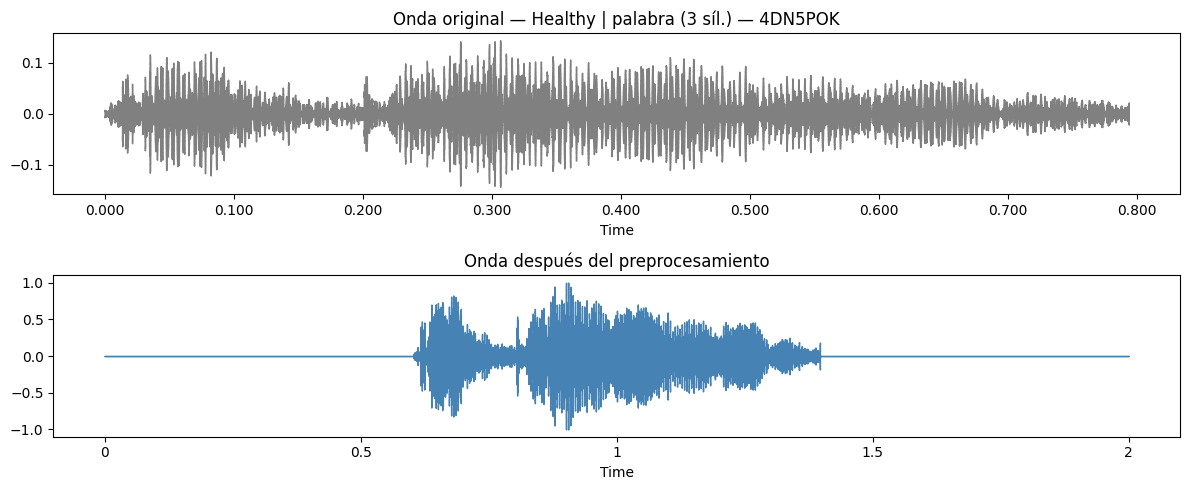


✅ Sección 4 (v5) completada. Listo para extracción de embeddings (Sección 5).


In [2]:
# ===============================================================_
# ITELv5 - SECCIÓN 5: EXTRACCIÓN Y CACHEO DE EMBEDDINGS (HuBERT)
# ===============================================================_
%run "./ITELv5_01_CONFIGURACION.ipynb"
%run "./ITELv5_04_PREPROCESAMIENTO.ipynb"  # importa procesar_audio()

import torch, torchaudio, numpy as np, pandas as pd
from pathlib import Path
from tqdm import tqdm

In [3]:
# 5.1 - Carga de modelo multilingue wav2vec2-large-xlsr-53
#
# Sustituye HuBERT BASE (solo ingles) por wav2vec2-large-xlsr-53
# entrenado en 53 idiomas — permite clasificar TEL en checo, ingles, etc.
# Embedding dim: 1024 -> 6 stats x 1024 = 6144 dims totales
import importlib, subprocess, sys
if importlib.util.find_spec('transformers') is None:
    subprocess.run([sys.executable,'-m','pip','install','transformers','--quiet'],check=True)
from transformers import Wav2Vec2Model, Wav2Vec2FeatureExtractor

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo: {device}')

XLSR_MODEL  = 'facebook/wav2vec2-large-xlsr-53'
MODEL_CACHE = str(ITELConfig.MODELS_DIR / 'xlsr53_cache')
print(f'Cargando {XLSR_MODEL} ... (primera vez ~1 GB)')
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(XLSR_MODEL, cache_dir=MODEL_CACHE)
xlsr_model = Wav2Vec2Model.from_pretrained(XLSR_MODEL, cache_dir=MODEL_CACHE).to(device)
xlsr_model.eval()
print('Modelo wav2vec2-large-xlsr-53 listo.')

Dispositivo: cpu
Cargando facebook/wav2vec2-large-xlsr-53 ... (primera vez ~1 GB)


preprocessor_config.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

c:\Users\USER\Documents\GitHub\ITEL\.venv\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\USER\Documents\GitHub\ITEL\assets\models\xlsr53_cache\models--facebook--wav2vec2-large-xlsr-53. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.27G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-large-xlsr-53
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Modelo wav2vec2-large-xlsr-53 listo.


In [4]:
# 5.2 - Extraccion de embeddings (6144 dims = 6 stats x 1024)
def extraer_embedding(ruta):
    y, sr, estado = procesar_audio(ruta)
    if y is None:
        return None
    y = y.astype(np.float32)
    # feature_extractor normaliza y espera numpy 1D a 16 kHz
    inputs = feature_extractor(y, sampling_rate=16000,
                                return_tensors='pt', padding=False)
    input_values = inputs.input_values.to(device)
    with torch.inference_mode():
        outputs = xlsr_model(input_values)
    features = outputs.last_hidden_state.squeeze(0).cpu()  # (T, 1024)
    T = features.shape[0]
    mean_emb  = features.mean(dim=0)
    std_emb   = features.std(dim=0)
    first_25  = features[: max(1, T // 4)].mean(dim=0)
    last_25   = features[-max(1, T // 4) :].mean(dim=0)
    delta     = first_25 - last_25
    # Slope vectorizado (correlacion de Pearson para las 1024 dims)
    x           = torch.arange(T, dtype=torch.float32)
    x_centered  = x - x.mean()
    f_centered  = features - features.mean(dim=0)
    numerator   = x_centered @ f_centered                        # (1024,)
    denominator = x_centered.norm() * f_centered.norm(dim=0).clamp(min=1e-8)
    slope_emb   = numerator / denominator
    slope_emb   = torch.where(features.var(dim=0) < 1e-10,
                               torch.zeros(1024), slope_emb)
    emb = torch.cat([mean_emb, std_emb, first_25, last_25, delta, slope_emb]).numpy()
    return emb  # (6144,)

In [5]:
# 5.3 - Cargar listado de audios (desde gestión de contenido v5)

# Usa la nueva ruta ITELConfig.CSV_DIR
csv_path = ITELConfig.CSV_DIR / 'gestion_contenido_v5.csv'

if csv_path.exists():
    df_audios = pd.read_csv(csv_path)
else:
    raise FileNotFoundError(f'{csv_path} no existe. Ejecuta ITELv5_03_GESTION_CONTENIDO primero.')
print(f'✅ {len(df_audios)} audios listos para procesar.')
display(df_audios.head())

✅ 3730 audios listos para procesar.


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre,ruta
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...


In [6]:
# 5.4 - Extracción para todos los audios (o cargar si ya existen)

# Actualizado para usar la nueva carpeta PROCESADOS_DIR
emb_dir = ITELConfig.PROCESADOS_DIR 
npy_file = emb_dir / 'embeddings_v5.npy'
info_file = emb_dir / 'embeddings_info_v5.csv'

if npy_file.exists() and info_file.exists():
    X = np.load(npy_file)
    info = pd.read_csv(info_file)
    print('📄 Cargando embeddings existentes de disco.')
else:
    embeddings, meta = [], []
    print('\n🎧 Iniciando extracción de embeddings...\n')
    for _, row in tqdm(df_audios.iterrows(), total=len(df_audios), desc='Embeddings'):
        emb = extraer_embedding(row['ruta'])
        if emb is None:
            continue
        embeddings.append(emb)
        meta.append({
            'categoria': row.get('categoria'),
            'subcarpeta': row.get('subcarpeta'),
            'tipo': row.get('tipo'),
            'silabas': row.get('silabas'),
            'etiqueta': row.get('etiqueta'),
            'nombre': row.get('nombre')
        })
    X = np.stack(embeddings)
    info = pd.DataFrame(meta)
    
    # La carpeta ya debe existir (verificada por 01_CONFIGURACION)
    # emb_dir.mkdir(parents=True, exist_ok=True) # <- Línea eliminada
    
    np.save(npy_file, X)
    info.to_csv(info_file, index=False)
    print(f'💾 Guardado: {npy_file} y {info_file}')

print('Shape X:', X.shape)
display(info.head())


🎧 Iniciando extracción de embeddings...



Embeddings:   0%|          | 1/3730 [00:00<23:46,  2.61it/s]

model.safetensors:   0%|          | 0.00/1.27G [00:00<?, ?B/s]

Embeddings: 100%|██████████| 3730/3730 [17:01<00:00,  3.65it/s]

💾 Guardado: C:\Users\USER\Documents\GitHub\ITEL\research\processed_data\embeddings_v5.npy y C:\Users\USER\Documents\GitHub\ITEL\research\processed_data\embeddings_info_v5.csv
Shape X: (3730, 6144)


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav


In [7]:
# 5.5 - Resumen y verificación de cacheo
print('✅ Embeddings generados/cargados correctamente')
print(' - Shape X:', X.shape)
print(' - Registros info:', len(info))
print(' - Rutas de cache:')
print('    *', npy_file)
print('    *', info_file)

# Muestra rápida de metadata
try:
    display(info.head())
except Exception:
    print(info.head())

✅ Embeddings generados/cargados correctamente
 - Shape X: (3730, 6144)
 - Registros info: 3730
 - Rutas de cache:
    * C:\Users\USER\Documents\GitHub\ITEL\research\processed_data\embeddings_v5.npy
    * C:\Users\USER\Documents\GitHub\ITEL\research\processed_data\embeddings_info_v5.csv


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav
